In [2]:
import re, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("spam mail.csv")
print(df.shape)
df.head()

(5572, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Category    0
Message     0
dtype: int64
Duplicates: 415
Category
ham     4825
spam     747
Name: count, dtype: int64


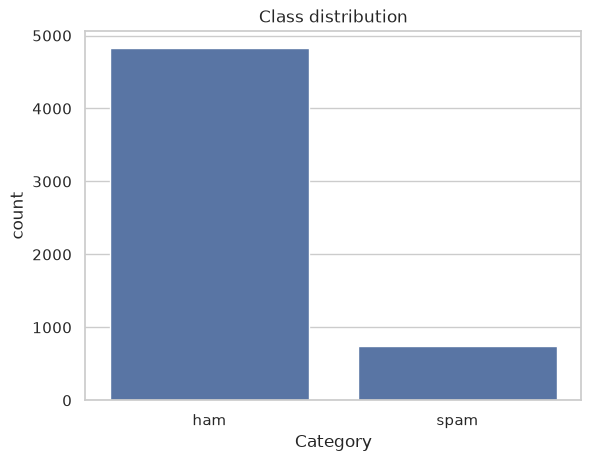

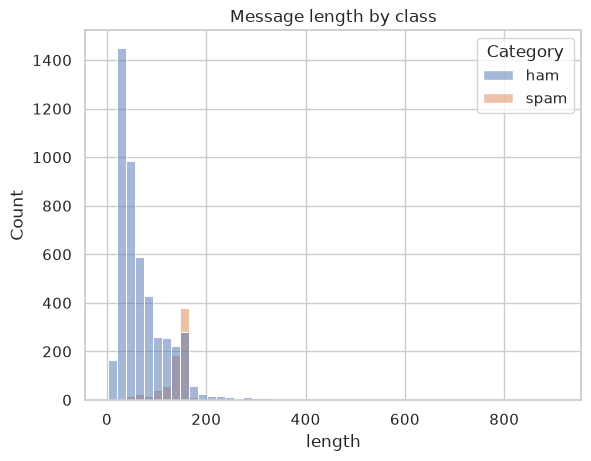

After removing duplicates: (5157, 3)


In [3]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df["Category"].value_counts())

sns.countplot(data=df, x="Category", order=["ham", "spam"])
plt.title("Class distribution")
plt.show()

df["length"] = df["Message"].str.len()
sns.histplot(data=df, x="length", hue="Category", bins=50)
plt.title("Message length by class")
plt.show()

# remove duplicates so the same message can't appear in both train and test
df = df.drop_duplicates(subset="Message").reset_index(drop=True)
print("After removing duplicates:", df.shape)

In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"(https?://\S+|www\.\S+)", " urltoken ", text)
    text = re.sub(r"\S+@\S+", " emailtoken ", text)
    text = re.sub(r"[£$€]\s?\d*[\d,.]*", " moneytoken ", text)
    text = re.sub(r"\b\d{5,}\b", " longnumtoken ", text)
    text = re.sub(r"\d+", " numtoken ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["clean"] = df["Message"].apply(clean_text)
df["label"] = (df["Category"] == "spam").astype(int)   # spam = 1

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2,
    random_state=RANDOM_STATE, stratify=df["label"])
print(X_train.shape, X_test.shape)

(4125,) (1032,)


In [5]:
def make_pipeline(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                                  min_df=2, sublinear_tf=True)),
        ("clf", clf),
    ])

models = {
    "Naive Bayes":         MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", C=10),
    "Linear SVM":          LinearSVC(class_weight="balanced", C=1),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                  random_state=RANDOM_STATE, n_jobs=-1),
}

results, fitted = [], {}
for name, clf in models.items():
    pipe = make_pipeline(clf).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({"Model": name,
                    "Accuracy":  accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Recall":    recall_score(y_test, pred),
                    "F1":        f1_score(y_test, pred)})

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1
0,Linear SVM,0.9874,0.9675,0.9297,0.9482
1,Naive Bayes,0.9874,0.9832,0.9141,0.9474
2,Logistic Regression,0.9864,0.9597,0.9297,0.9444
3,Random Forest,0.9855,1.0000,0.8828,0.9378


Best model: Linear SVM
              precision    recall  f1-score   support

         ham     0.9901    0.9956    0.9928       904
        spam     0.9675    0.9297    0.9482       128

    accuracy                         0.9874      1032
   macro avg     0.9788    0.9626    0.9705      1032
weighted avg     0.9873    0.9874    0.9873      1032



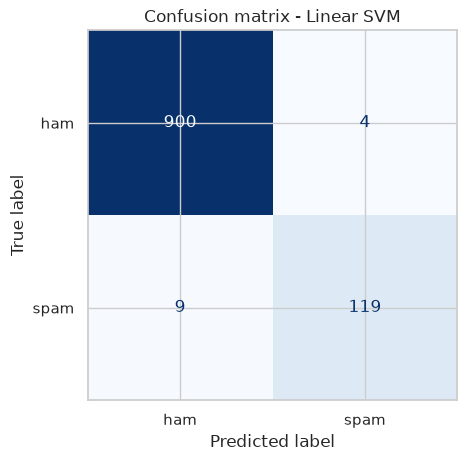

,Model,CV F1 mean,CV F1 std
0,Naive Bayes,0.9519,0.0055
2,Linear SVM,0.9489,0.0209
3,Random Forest,0.9458,0.0147
1,Logistic Regression,0.9454,0.0232


In [6]:
best_name = results_df.loc[0, "Model"]
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Confusion matrix - {best_name}")
plt.show()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, clf in models.items():
    s = cross_val_score(make_pipeline(clf), df["clean"], df["label"], cv=skf, scoring="f1")
    cv_rows.append({"Model": name, "CV F1 mean": s.mean(), "CV F1 std": s.std()})
pd.DataFrame(cv_rows).sort_values("CV F1 mean", ascending=False).round(4)

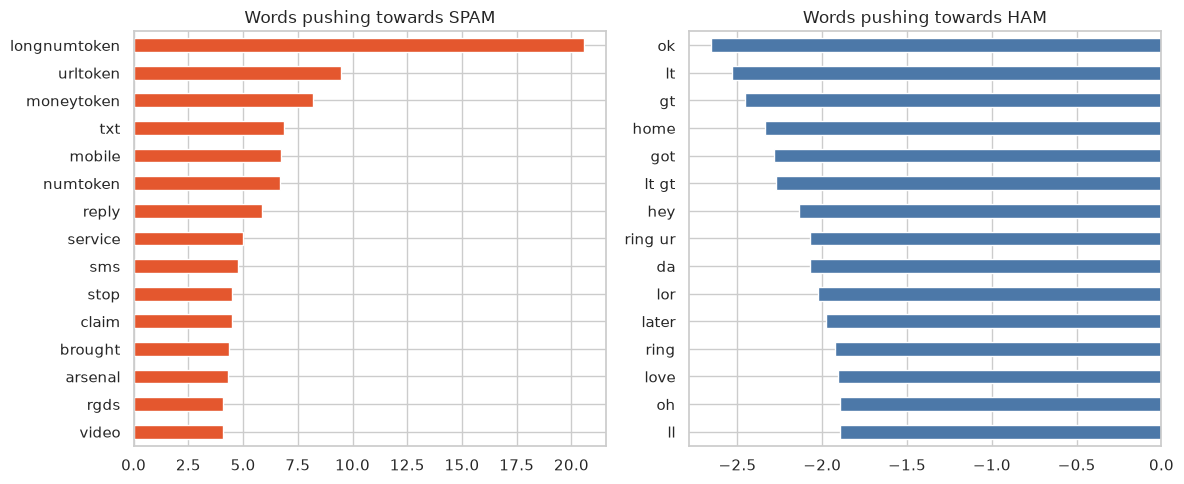

Missed spam:


,Message
3630,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg £1.50"
3817,TBS/PERSOLVO. been chasing us since Sept for£38 definitely not paying now thanks to your information. We will ignore them. Kath. Manches...
2541,"Hello darling how are you today? I would love to have a chat, why dont you tell me what you look like and what you are in to sexy?"
496,#ERROR!
4977,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?
2637,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a w...
4605,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the adult parties..."
5127,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS...
3884,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ..."


Good mail flagged as spam:


,Message
4409,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &lt;#&gt;
3514,"It‘s £6 to get in, is that ok?"
2884,Your bill at 3 is £33.65 so thats not bad!
4797,K k:) sms chat with me.


In [7]:
lr = make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", C=10)).fit(X_train, y_train)
feat = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=feat)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
coefs.sort_values(ascending=False).head(15)[::-1].plot(kind="barh", ax=ax[0], color="#E4572E")
ax[0].set_title("Words pushing towards SPAM")
coefs.sort_values().head(15)[::-1].plot(kind="barh", ax=ax[1], color="#4C78A8")
ax[1].set_title("Words pushing towards HAM")
plt.tight_layout(); plt.show()

pd.set_option("display.max_colwidth", 140)
test_df = pd.DataFrame({"Message": df.loc[X_test.index, "Message"],
                        "actual": y_test, "predicted": y_pred})
print("Missed spam:")
display(test_df[(test_df.actual == 1) & (test_df.predicted == 0)][["Message"]].head(10))
print("Good mail flagged as spam:")
display(test_df[(test_df.actual == 0) & (test_df.predicted == 1)][["Message"]].head(10))

In [8]:
joblib.dump(best_model, "spam_classifier.joblib")

def predict_message(text, model=best_model):
    label = model.predict([clean_text(text)])[0]
    return "SPAM" if label == 1 else "HAM (not spam)"

samples = [
    "Congratulations! You have won a £1000 prize. Call 09061701461 now to claim your reward!",
    "Hey, are we still meeting for lunch at 1 pm tomorrow?",
    "URGENT! Your account has been selected for a free iPhone. Click www.claim-prize.com now",
    "Can you send me the notes from yesterday's class?",
]
for s in samples:
    print(f"{predict_message(s):<16} | {s}")

SPAM             | Congratulations! You have won a £1000 prize. Call 09061701461 now to claim your reward!
HAM (not spam)   | Hey, are we still meeting for lunch at 1 pm tomorrow?
SPAM             | URGENT! Your account has been selected for a free iPhone. Click www.claim-prize.com now
HAM (not spam)   | Can you send me the notes from yesterday's class?
